# MURA X-Ray Abnormality Detection
### Model comparison notebook

**Goal:** EDA → ANN/CNN baselines → LeNet → AlexNet → VGG16/VGG19 → GoogLeNet-style Inception v1 → InceptionV3 → ResNet50 → DenseNet121 → comparison.

**Labels:** `0 = Normal`, `1 = Abnormal`

**Training subset:** 2,000 training images and 500 validation images; one epoch per model for a lightweight first run.

**Important:** MURA labels are Normal/Abnormal labels, not a confirmed fracture-only diagnosis.

## STEP 1 — Import Libraries
**What we are doing:** Loading the libraries needed for data handling, image processing, graphs, and deep learning.


In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image

print("TensorFlow:", tf.__version__)


TensorFlow: 2.21.0


## STEP 2 — Set MURA Dataset Path
**What we are doing:** Connecting the notebook to your downloaded MURA dataset.


In [5]:
DATASET_PATH = r"C:\Users\ASUS\Downloads\archive (14)\MURA-v1.1"

TRAIN_PATH = os.path.join(DATASET_PATH, "train")
VALID_PATH = os.path.join(DATASET_PATH, "valid")

print("Dataset:", os.path.exists(DATASET_PATH))
print("Train:", os.path.exists(TRAIN_PATH))
print("Valid:", os.path.exists(VALID_PATH))


Dataset: True
Train: True
Valid: True


## STEP 3 — Create Dataset Table
**What we are doing:** Reading every X-ray path and assigning Normal/Abnormal labels and body parts.


In [7]:
def create_dataframe(root_dir):
    data = []

    for root, _, files in os.walk(root_dir):
        for file in files:
            if file.lower().endswith(".png"):
                path = os.path.join(root, file)
                p = path.lower()

                if "positive" in p:
                    label = 1
                elif "negative" in p:
                    label = 0
                else:
                    continue

                body_part = "Unknown"
                for part in [
                    "XR_ELBOW", "XR_FINGER", "XR_FOREARM",
                    "XR_HAND", "XR_HUMERUS", "XR_SHOULDER", "XR_WRIST"
                ]:
                    if part.lower() in p:
                        body_part = part.replace("XR_", "")
                        break

                data.append([path, label, body_part])

    return pd.DataFrame(
        data,
        columns=["image_path", "label", "body_part"]
    )

train_df = create_dataframe(TRAIN_PATH)
valid_df = create_dataframe(VALID_PATH)

print("Training images:", len(train_df))
print("Validation images:", len(valid_df))


Training images: 36807
Validation images: 3197


## STEP 4 — EDA: Normal vs Abnormal
**What we are doing:** Checking the class distribution in the training dataset.


class
Normal      21939
Abnormal    14868
Name: count, dtype: int64


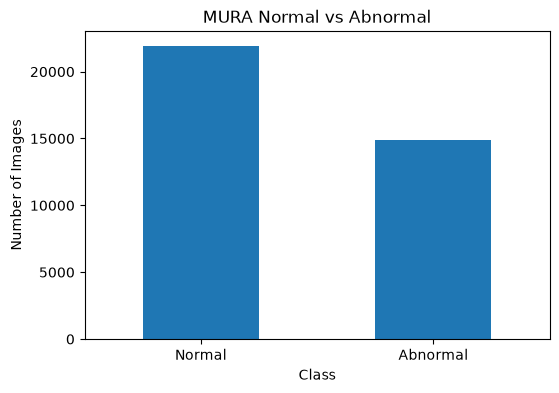

In [9]:
train_df["class"] = train_df["label"].map({0: "Normal", 1: "Abnormal"})

print(train_df["class"].value_counts())

train_df["class"].value_counts().plot(kind="bar", figsize=(6,4))
plt.title("MURA Normal vs Abnormal")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.show()


## STEP 5 — EDA: Actual X-Ray Samples
**What we are doing:** Visually inspecting Normal and Abnormal X-rays.


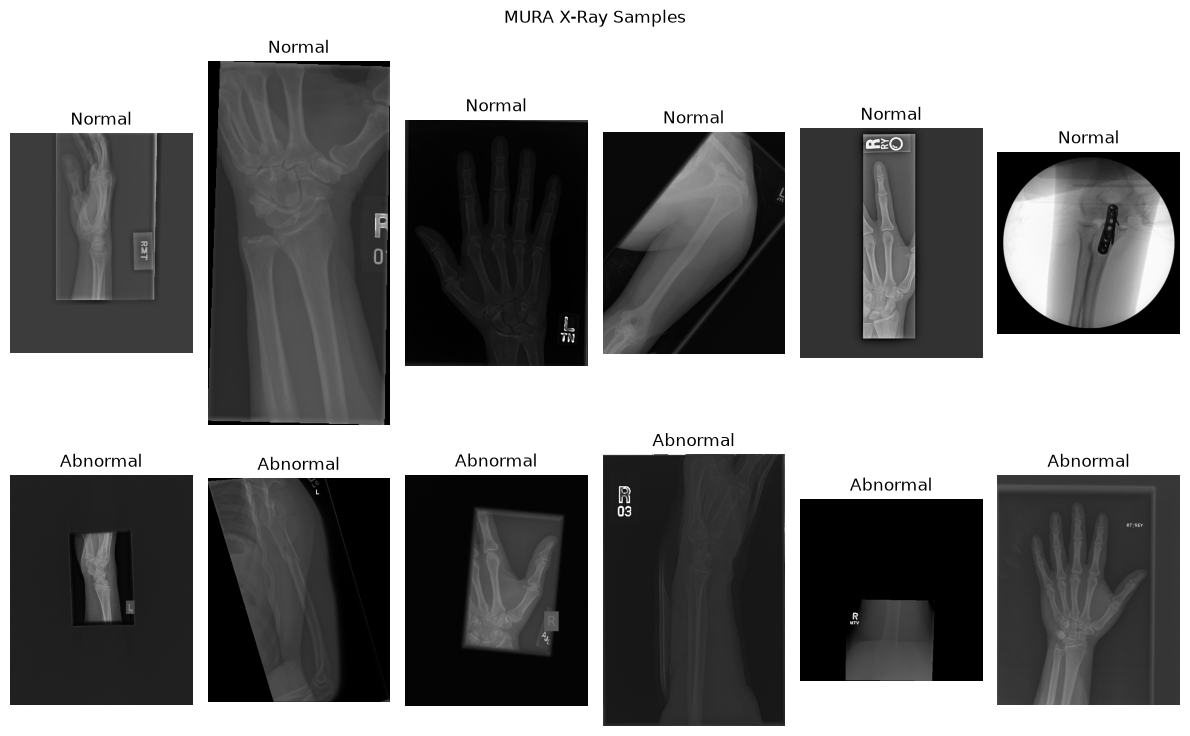

In [11]:
normal = train_df[train_df.label == 0].sample(6, random_state=42)
abnormal = train_df[train_df.label == 1].sample(6, random_state=42)

plt.figure(figsize=(12,8))

for i, (_, row) in enumerate(normal.iterrows()):
    plt.subplot(2, 6, i+1)
    plt.imshow(Image.open(row.image_path), cmap="gray")
    plt.title("Normal")
    plt.axis("off")

for i, (_, row) in enumerate(abnormal.iterrows()):
    plt.subplot(2, 6, i+7)
    plt.imshow(Image.open(row.image_path), cmap="gray")
    plt.title("Abnormal")
    plt.axis("off")

plt.suptitle("MURA X-Ray Samples")
plt.tight_layout()
plt.show()


## STEP 6 — EDA: Body-Part Distribution
**What we are doing:** Checking how X-rays are distributed across elbow, finger, forearm, hand, humerus, shoulder, and wrist.


body_part
WRIST       9751
SHOULDER    8379
HAND        5543
FINGER      5106
ELBOW       4931
FOREARM     1825
HUMERUS     1272
Name: count, dtype: int64


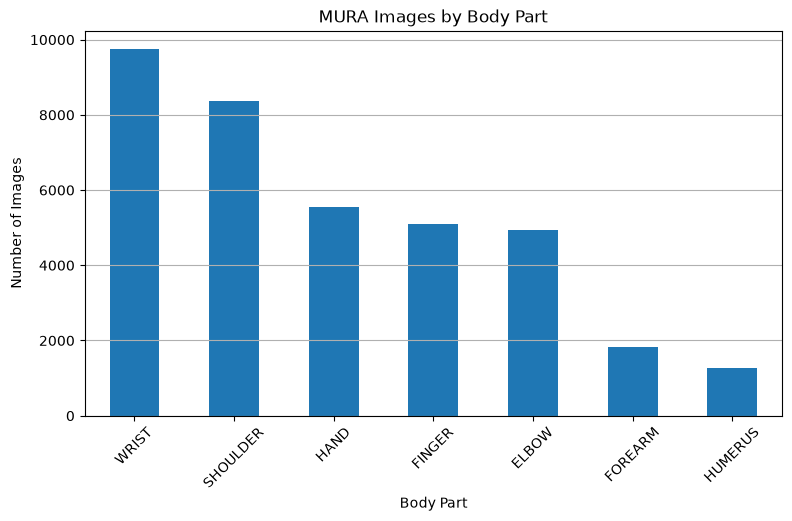

In [13]:
body_counts = train_df["body_part"].value_counts()

print(body_counts)

body_counts.plot(kind="bar", figsize=(9,5))
plt.title("MURA Images by Body Part")
plt.xlabel("Body Part")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()


## STEP 7 — Create Fast Training Subset
**What we are doing:** Using 2,000 training and 500 validation images so training is practical on your CPU.


In [15]:
train_small = train_df.sample(2000, random_state=42)
valid_small = valid_df.sample(500, random_state=42)

print("Training:", len(train_small))
print("Validation:", len(valid_small))


Training: 2000
Validation: 500


In [17]:
def load_gray(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_png(img, channels=1)
    img = tf.image.resize(img, (64, 64))
    img = img / 255.0
    return img, label

train_anncnn = tf.data.Dataset.from_tensor_slices(
    (train_small.image_path.values, train_small.label.values)
).map(load_gray).batch(32)

valid_anncnn = tf.data.Dataset.from_tensor_slices(
    (valid_small.image_path.values, valid_small.label.values)
).map(load_gray).batch(32)

print("ANN/CNN dataset ready")


ANN/CNN dataset ready


In [19]:
ann = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64,64,1)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

ann.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

ann.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 4096)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         524,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 532,737 (2.03 MB)

 Trainable params: 532,737 (2.03 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
history_ann = ann.fit(
    train_anncnn,
    validation_data=valid_anncnn,
    epochs=1
)


C:\Users\ASUS\.eclipse\ photos\envs\mura_tf\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - accuracy: 0.5415 - loss: 0.7363 - val_accuracy: 0.5220 - val_loss: 0.6943


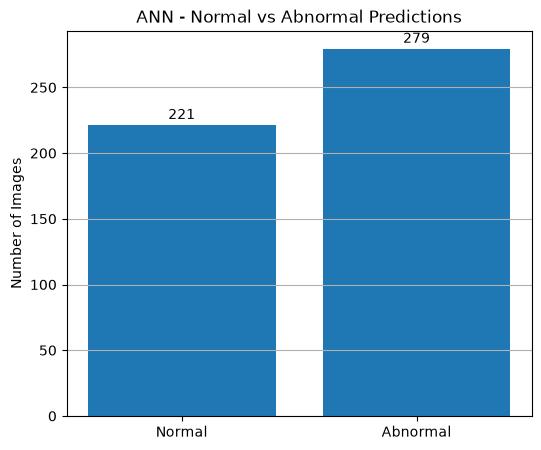

In [22]:
ann_pred = (ann.predict(valid_anncnn, verbose=0) >= 0.5).astype(int).flatten()

ann_normal = (ann_pred == 0).sum()
ann_abnormal = (ann_pred == 1).sum()

plt.figure(figsize=(6,5))
bars = plt.bar(["Normal", "Abnormal"], [ann_normal, ann_abnormal])
plt.title("ANN - Normal vs Abnormal Predictions")
plt.ylabel("Number of Images")

for bar, value in zip(bars, [ann_normal, ann_abnormal]):
    plt.text(bar.get_x() + bar.get_width()/2, value + 5, str(value), ha="center")

plt.grid(axis="y")
plt.show()


In [24]:
cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64,64,1)),
    tf.keras.layers.Conv2D(32, (3,3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2,2),
    tf.keras.layers.Conv2D(64, (3,3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2,2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

cnn.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

cnn.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 62, 62, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 31, 31, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 29, 29, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 12544)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 128)                 │       1,605,760 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,624,705 (6.20 MB)

 Trainable params: 1,624,705 (6.20 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
history_cnn = cnn.fit(
    train_anncnn,
    validation_data=valid_anncnn,
    epochs=1
)


C:\Users\ASUS\.eclipse\ photos\envs\mura_tf\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 85ms/step - accuracy: 0.5770 - loss: 0.6864 - val_accuracy: 0.5240 - val_loss: 0.6861


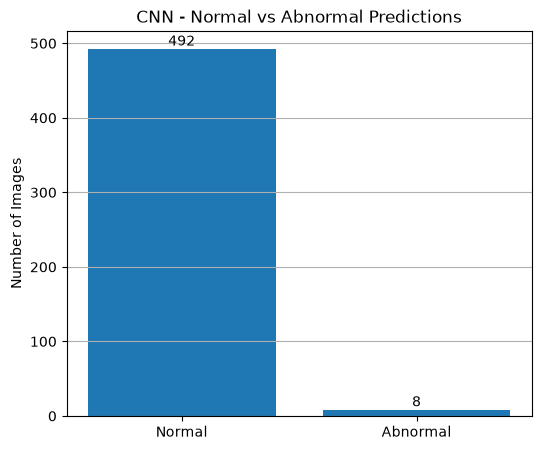

In [27]:
cnn_pred = (cnn.predict(valid_anncnn, verbose=0) >= 0.5).astype(int).flatten()

cnn_normal = (cnn_pred == 0).sum()
cnn_abnormal = (cnn_pred == 1).sum()

plt.figure(figsize=(6,5))
bars = plt.bar(["Normal", "Abnormal"], [cnn_normal, cnn_abnormal])
plt.title("CNN - Normal vs Abnormal Predictions")
plt.ylabel("Number of Images")

for bar, value in zip(bars, [cnn_normal, cnn_abnormal]):
    plt.text(bar.get_x() + bar.get_width()/2, value + 5, str(value), ha="center")

plt.grid(axis="y")
plt.show()


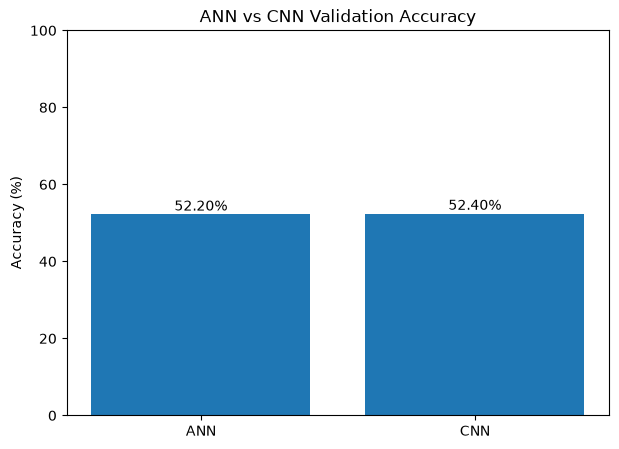

In [29]:
ann_acc = history_ann.history["val_accuracy"][-1] * 100
cnn_acc = history_cnn.history["val_accuracy"][-1] * 100

plt.figure(figsize=(7,5))
bars = plt.bar(["ANN", "CNN"], [ann_acc, cnn_acc])
plt.title("ANN vs CNN Validation Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for bar, value in zip(bars, [ann_acc, cnn_acc]):
    plt.text(bar.get_x() + bar.get_width()/2, value + 1, f"{value:.2f}%", ha="center")

plt.show()


## STEP 8 — Prepare Images for ResNet50 and DenseNet121
**Why this step is needed:** ResNet50 and DenseNet121 expect 3-channel RGB images and are commonly used with 224×224 inputs. The existing ANN/CNN models use 64×64 grayscale images, so we create separate datasets for these models.

**Note:** This project predicts the MURA dataset labels (`Normal` vs `Abnormal`). It does not independently confirm a specific fracture.

In [ ]:
IMG_SIZE_TRANSFER = (224, 224)
TRANSFER_BATCH_SIZE = 8  # Smaller batches help reduce CPU/RAM usage.

def load_rgb_for_transfer(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_png(image, channels=1)
    image = tf.image.resize(image, IMG_SIZE_TRANSFER)
    image = tf.image.grayscale_to_rgb(image)
    image = tf.cast(image, tf.float32)
    return image, tf.cast(label, tf.float32)

train_transfer = tf.data.Dataset.from_tensor_slices(
    (train_small["image_path"].values, train_small["label"].values)
).map(load_rgb_for_transfer, num_parallel_calls=tf.data.AUTOTUNE).batch(TRANSFER_BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

valid_transfer = tf.data.Dataset.from_tensor_slices(
    (valid_small["image_path"].values, valid_small["label"].values)
).map(load_rgb_for_transfer, num_parallel_calls=tf.data.AUTOTUNE).batch(TRANSFER_BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Transfer-learning datasets ready.")

## STEP 9 — ResNet50 Model
**What it does:** ResNet50 uses residual connections to help information flow through a deep neural network. We use ImageNet-pretrained convolutional features as a frozen feature extractor and train a small binary classification head on MURA.

**First run note:** `weights="imagenet"` may download pretrained weights and requires an internet connection. If downloading is unavailable, change it to `weights=None` (results may be substantially weaker and training from scratch is more demanding).

In [ ]:
from tensorflow.keras.applications import ResNet50, DenseNet121
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Dense, Dropout, Lambda
from tensorflow.keras.models import Model

resnet_base = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)
resnet_base.trainable = False

resnet_input = Input(shape=(224, 224, 3))
resnet_preprocessed = Lambda(resnet_preprocess, name="resnet_preprocessing")(resnet_input)
resnet_features = resnet_base(resnet_preprocessed, training=False)
resnet_features = GlobalAveragePooling2D()(resnet_features)
resnet_features = Dense(128, activation="relu")(resnet_features)
resnet_features = Dropout(0.3)(resnet_features)
resnet_output = Dense(1, activation="sigmoid")(resnet_features)

resnet_model = Model(resnet_input, resnet_output, name="MURA_ResNet50")
resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)
resnet_model.summary()

In [ ]:
history_resnet = resnet_model.fit(
    train_transfer,
    validation_data=valid_transfer,
    epochs=1
)

resnet_model.save("MURA_ResNet50.keras")
print("Saved MURA_ResNet50.keras")

## STEP 10 — DenseNet121 Model
**What it does:** DenseNet121 connects each layer to later layers within dense blocks, encouraging feature reuse. Like ResNet50, we freeze its pretrained feature extractor and train a small classification head. Compare measured validation metrics rather than assuming one architecture is best.

In [ ]:
densenet_base = DenseNet121(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)
densenet_base.trainable = False

densenet_input = Input(shape=(224, 224, 3))
densenet_features = densenet_base(densenet_input, training=False)
densenet_features = GlobalAveragePooling2D()(densenet_features)
densenet_features = Dense(128, activation="relu")(densenet_features)
densenet_features = Dropout(0.3)(densenet_features)
densenet_output = Dense(1, activation="sigmoid")(densenet_features)

densenet_model = Model(densenet_input, densenet_output, name="MURA_DenseNet121")
densenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)
densenet_model.summary()

In [ ]:
history_densenet = densenet_model.fit(
    train_transfer,
    validation_data=valid_transfer,
    epochs=1
)

densenet_model.save("MURA_DenseNet121.keras")
print("Saved MURA_DenseNet121.keras")

## STEP 10B — LeNet and AlexNet
LeNet is a small early CNN; AlexNet is a deeper CNN using ReLU and dropout. These adaptations use the existing 64×64 grayscale datasets (`train_anncnn` and `valid_anncnn`) to keep computation manageable.

In [ ]:
from tensorflow.keras.layers import Conv2D, AveragePooling2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.models import Sequential

# LeNet-5-inspired compact CNN adapted to 64x64 grayscale images.
lenet_model = Sequential([
    Input(shape=(64, 64, 1)),
    Conv2D(6, (5, 5), activation="tanh", padding="same"),
    AveragePooling2D((2, 2)),
    Conv2D(16, (5, 5), activation="tanh"),
    AveragePooling2D((2, 2)),
    Flatten(),
    Dense(120, activation="tanh"),
    Dense(84, activation="tanh"),
    Dense(1, activation="sigmoid")
], name="MURA_LeNet")
lenet_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                    loss="binary_crossentropy",
                    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
lenet_model.summary()
history_lenet = lenet_model.fit(train_anncnn, validation_data=valid_anncnn, epochs=1)
lenet_model.save("MURA_LeNet.keras")
print("Saved MURA_LeNet.keras")

In [ ]:
# AlexNet-inspired compact adaptation for 64x64 grayscale inputs.
alexnet_model = Sequential([
    Input(shape=(64, 64, 1)),
    Conv2D(32, (5, 5), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),
    Conv2D(96, (3, 3), padding="same", activation="relu"),
    Conv2D(64, (3, 3), padding="same", activation="relu"),
    Conv2D(64, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(256, activation="relu"), Dropout(0.5),
    Dense(128, activation="relu"), Dropout(0.5),
    Dense(1, activation="sigmoid")
], name="MURA_AlexNet")
alexnet_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                      loss="binary_crossentropy",
                      metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
alexnet_model.summary()
history_alexnet = alexnet_model.fit(train_anncnn, validation_data=valid_anncnn, epochs=1)
alexnet_model.save("MURA_AlexNet.keras")
print("Saved MURA_AlexNet.keras")

## STEP 10C — VGG16 and VGG19
VGG16 has 13 convolutional plus 3 fully connected weight-bearing layers; VGG19 has 16 convolutional plus 3 fully connected layers. We use ImageNet-pretrained convolutional bases as frozen feature extractors and train a small binary classification head. Preprocessing is included inside each model.

In [ ]:
from tensorflow.keras.applications import VGG16, VGG19, InceptionV3
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.applications.vgg19 import preprocess_input as vgg19_preprocess
from tensorflow.keras.applications.inception_v3 import preprocess_input as inception_preprocess

def build_pretrained_classifier(base_model, model_name, preprocess_fn=None, learning_rate=1e-3):
    model_input = Input(shape=(224, 224, 3))
    x = model_input
    if preprocess_fn is not None:
        x = Lambda(preprocess_fn, name=f"{model_name.lower()}_preprocessing")(x)
    x = base_model(x, training=False)
    x = GlobalAveragePooling2D()(x)
    x = Dense(128, activation="relu")(x)
    x = Dropout(0.3)(x)
    model_output = Dense(1, activation="sigmoid")(x)
    model = Model(model_input, model_output, name=model_name)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="binary_crossentropy",
                  metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
    return model

vgg16_base = VGG16(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
vgg16_base.trainable = False
vgg16_model = build_pretrained_classifier(vgg16_base, "MURA_VGG16", vgg_preprocess)
vgg16_model.summary()
history_vgg16 = vgg16_model.fit(train_transfer, validation_data=valid_transfer, epochs=1)
vgg16_model.save("MURA_VGG16.keras")
print("Saved MURA_VGG16.keras")

In [ ]:
vgg19_base = VGG19(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
vgg19_base.trainable = False
vgg19_model = build_pretrained_classifier(vgg19_base, "MURA_VGG19", vgg19_preprocess)
vgg19_model.summary()
history_vgg19 = vgg19_model.fit(train_transfer, validation_data=valid_transfer, epochs=1)
vgg19_model.save("MURA_VGG19.keras")
print("Saved MURA_VGG19.keras")

## STEP 10D — GoogLeNet-style Inception v1
Keras does not provide the original GoogLeNet v1 as a standard application model, so the code below builds a compact **GoogLeNet-inspired** model with parallel Inception-style branches. It is not an exact reproduction of the original paper architecture and is trained from scratch.

In [ ]:
def inception_block(x, filters, name):
    f1, f3_reduce, f3, f5_reduce, f5, f_pool = filters
    b1 = Conv2D(f1, (1, 1), padding="same", activation="relu", name=f"{name}_1x1")(x)
    b3 = Conv2D(f3_reduce, (1, 1), padding="same", activation="relu", name=f"{name}_3x3_reduce")(x)
    b3 = Conv2D(f3, (3, 3), padding="same", activation="relu", name=f"{name}_3x3")(b3)
    b5 = Conv2D(f5_reduce, (1, 1), padding="same", activation="relu", name=f"{name}_5x5_reduce")(x)
    b5 = Conv2D(f5, (5, 5), padding="same", activation="relu", name=f"{name}_5x5")(b5)
    bp = MaxPooling2D((3, 3), strides=(1, 1), padding="same", name=f"{name}_pool")(x)
    bp = Conv2D(f_pool, (1, 1), padding="same", activation="relu", name=f"{name}_pool_proj")(bp)
    return tf.keras.layers.Concatenate(axis=-1, name=f"{name}_concat")([b1, b3, b5, bp])

googlenet_input = Input(shape=(224, 224, 3))
x = Conv2D(32, (7, 7), strides=2, padding="same", activation="relu")(googlenet_input)
x = MaxPooling2D((3, 3), strides=2, padding="same")(x)
x = Conv2D(32, (1, 1), activation="relu")(x)
x = Conv2D(64, (3, 3), padding="same", activation="relu")(x)
x = MaxPooling2D((3, 3), strides=2, padding="same")(x)
x = inception_block(x, (32, 24, 32, 8, 16, 16), "inception_3a")
x = inception_block(x, (64, 32, 48, 8, 16, 16), "inception_3b")
x = MaxPooling2D((3, 3), strides=2, padding="same")(x)
x = inception_block(x, (64, 32, 48, 8, 16, 16), "inception_4a")
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
googlenet_output = Dense(1, activation="sigmoid")(x)
googlenet_model = Model(googlenet_input, googlenet_output, name="MURA_GoogLeNet_InceptionV1_Inspired")
googlenet_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                        loss="binary_crossentropy",
                        metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
googlenet_model.summary()
history_googlenet = googlenet_model.fit(train_transfer, validation_data=valid_transfer, epochs=1)
googlenet_model.save("MURA_GoogLeNet_InceptionV1_Inspired.keras")
print("Saved MURA_GoogLeNet_InceptionV1_Inspired.keras")

## STEP 10E — InceptionV3
GoogLeNet is commonly called Inception v1. InceptionV3 is a later, different architecture in the Inception family. This section uses Keras's ImageNet-pretrained InceptionV3 as a frozen feature extractor.

In [ ]:
inceptionv3_base = InceptionV3(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
inceptionv3_base.trainable = False
inceptionv3_model = build_pretrained_classifier(inceptionv3_base, "MURA_InceptionV3", inception_preprocess)
inceptionv3_model.summary()
history_inceptionv3 = inceptionv3_model.fit(train_transfer, validation_data=valid_transfer, epochs=1)
inceptionv3_model.save("MURA_InceptionV3.keras")
print("Saved MURA_InceptionV3.keras")

## STEP 11 — Evaluate and Compare All Models
This section calculates accuracy, precision, recall, F1-score, and ROC-AUC on the same validation subset for every trained model. Metrics are generated after the model-training cells have run.


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

y_true = valid_small["label"].to_numpy().astype(int)

def get_binary_metrics(model, dataset, y_true, model_name):
    probabilities = model.predict(dataset, verbose=0).reshape(-1)
    predictions = (probabilities >= 0.5).astype(int)
    return {
        "Model": model_name,
        "Accuracy (%)": round(accuracy_score(y_true, predictions) * 100, 2),
        "Precision": round(precision_score(y_true, predictions, zero_division=0), 4),
        "Recall": round(recall_score(y_true, predictions, zero_division=0), 4),
        "F1-score": round(f1_score(y_true, predictions, zero_division=0), 4),
        "ROC-AUC": round(roc_auc_score(y_true, probabilities), 4) if len(np.unique(y_true)) == 2 else np.nan
    }

results = [
    get_binary_metrics(ann, valid_anncnn, y_true, "ANN"),
    get_binary_metrics(cnn, valid_anncnn, y_true, "CNN"),
    get_binary_metrics(lenet_model, valid_anncnn, y_true, "LeNet"),
    get_binary_metrics(alexnet_model, valid_anncnn, y_true, "AlexNet"),
    get_binary_metrics(vgg16_model, valid_transfer, y_true, "VGG16"),
    get_binary_metrics(vgg19_model, valid_transfer, y_true, "VGG19"),
    get_binary_metrics(googlenet_model, valid_transfer, y_true, "GoogLeNet-inspired"),
    get_binary_metrics(inceptionv3_model, valid_transfer, y_true, "InceptionV3"),
    get_binary_metrics(resnet_model, valid_transfer, y_true, "ResNet50"),
    get_binary_metrics(densenet_model, valid_transfer, y_true, "DenseNet121")
]

results_df = pd.DataFrame(results)
display(results_df)

plt.figure(figsize=(13, 6))
bars = plt.bar(results_df["Model"], results_df["Accuracy (%)"])
plt.title("MURA Validation Accuracy: CNN Architectures")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 100)
for bar, value in zip(bars, results_df["Accuracy (%)"]):
    plt.text(bar.get_x() + bar.get_width()/2, value + 1, f"{value:.1f}%", ha="center", fontsize=8)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

results_df.to_csv("MURA_Model_Comparison.csv", index=False)
print("Saved MURA_Model_Comparison.csv")


## STEP 12 — How to Explain the Comparison
- **ANN:** Flattens pixels and learns with dense layers; it does not explicitly preserve spatial structure.
- **CNN:** Learns local image patterns with convolution and pooling.
- **LeNet:** Compact early CNN, adapted here for 64×64 grayscale images.
- **AlexNet:** Deeper CNN using ReLU and dropout; this is a lightweight adaptation, not the exact original ImageNet configuration.
- **VGG16 / VGG19:** Deep stacks of 3×3 convolutions; pretrained convolutional layers are frozen and a binary classification head is trained.
- **GoogLeNet-inspired:** Compact Inception-v1-style model with parallel convolution branches; not the exact original GoogLeNet.
- **InceptionV3:** A later Inception-family architecture, different from GoogLeNet/Inception v1.
- **ResNet50:** Uses residual/skip connections.
- **DenseNet121:** Uses dense connections to encourage feature reuse.
- **Precision:** Of images predicted Abnormal, the fraction truly labelled Abnormal.
- **Recall:** Of images labelled Abnormal, the fraction correctly identified.
- **F1-score:** Harmonic mean of precision and recall.
- **ROC-AUC:** Measures separation between the two labels across thresholds.

**Important limitations:** This notebook uses 2,000 training images, 500 validation images, and one epoch for a lightweight first comparison. Pretrained models use 224×224 RGB inputs; LeNet and AlexNet use 64×64 grayscale inputs. Results are exploratory and may vary. For stronger conclusions, use patient/study-aware splitting, a held-out test set, more epochs with early stopping, and class-imbalance handling. MURA labels are Normal/Abnormal, so describe this as X-ray abnormality classification rather than confirmed fracture diagnosis.


# STEP 13 — Vision Transformer (ViT)

This section adds a Vision Transformer after all existing CNN architectures. It uses the same `train_small` and `valid_small` splits already defined in this notebook. To reduce CPU/RAM use, transformer images are resized to 96 × 96 RGB and batched in small groups.

ViT divides an image into patches, embeds those patches, adds learnable positional embeddings, and processes them with self-attention blocks.

In [ ]:
# Prepare a smaller RGB dataset for transformer models
VIT_IMAGE_SIZE = 96
VIT_BATCH_SIZE = 8
TRANSFORMER_EPOCHS = 2  # Increase only if your system can handle the extra training time

def load_rgb_for_transformer(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_png(image, channels=1)
    image = tf.image.resize(image, (VIT_IMAGE_SIZE, VIT_IMAGE_SIZE))
    image = tf.image.grayscale_to_rgb(image)
    image = tf.cast(image, tf.float32) / 255.0
    return image, tf.cast(label, tf.float32)

def make_transformer_dataset(dataframe, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices(
        (dataframe["image_path"].values, dataframe["label"].values)
    )
    if shuffle:
        dataset = dataset.shuffle(len(dataframe), reshuffle_each_iteration=True)
    return (dataset
            .map(load_rgb_for_transformer, num_parallel_calls=tf.data.AUTOTUNE)
            .batch(VIT_BATCH_SIZE)
            .prefetch(tf.data.AUTOTUNE))

train_transformer = make_transformer_dataset(train_small, shuffle=True)
valid_transformer = make_transformer_dataset(valid_small, shuffle=False)

print("Transformer datasets ready.")
print("Input image shape:", (VIT_IMAGE_SIZE, VIT_IMAGE_SIZE, 3))

In [ ]:
# Vision Transformer building blocks
class LearnablePositionEmbedding(tf.keras.layers.Layer):
    def build(self, input_shape):
        self.position_embedding = self.add_weight(
            name="position_embedding",
            shape=(1, input_shape[1], input_shape[2]),
            initializer="random_normal",
            trainable=True
        )

    def call(self, inputs):
        return inputs + self.position_embedding

def vit_encoder_block(x, embed_dim=64, num_heads=4, mlp_dim=128, dropout_rate=0.1):
    # Multi-head self-attention
    shortcut = x
    x = tf.keras.layers.LayerNormalization(epsilon=1e-6)(x)
    x = tf.keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads,
        dropout=dropout_rate
    )(x, x)
    x = tf.keras.layers.Add()([shortcut, x])

    # Feed-forward network
    shortcut = x
    x = tf.keras.layers.LayerNormalization(epsilon=1e-6)(x)
    x = tf.keras.layers.Dense(mlp_dim, activation="gelu")(x)
    x = tf.keras.layers.Dropout(dropout_rate)(x)
    x = tf.keras.layers.Dense(embed_dim)(x)
    x = tf.keras.layers.Dropout(dropout_rate)(x)
    return tf.keras.layers.Add()([shortcut, x])

def build_vit_model():
    inputs = tf.keras.layers.Input(
        shape=(VIT_IMAGE_SIZE, VIT_IMAGE_SIZE, 3)
    )

    # 96x96 image -> 12x12 patches, each represented by a 64-D vector
    x = tf.keras.layers.Conv2D(
        filters=64, kernel_size=8, strides=8, padding="valid"
    )(inputs)
    x = tf.keras.layers.Reshape((144, 64))(x)
    x = LearnablePositionEmbedding()(x)

    for _ in range(3):
        x = vit_encoder_block(x, embed_dim=64, num_heads=4, mlp_dim=128)

    x = tf.keras.layers.LayerNormalization(epsilon=1e-6)(x)
    x = tf.keras.layers.GlobalAveragePooling1D()(x)
    x = tf.keras.layers.Dense(64, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)

    model = tf.keras.Model(inputs, outputs, name="MURA_Vision_Transformer")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
    )
    return model

vit_model = build_vit_model()
vit_model.summary()

In [ ]:
import time

vit_start_time = time.time()
history_vit = vit_model.fit(
    train_transformer,
    validation_data=valid_transformer,
    epochs=TRANSFORMER_EPOCHS
)
vit_training_seconds = time.time() - vit_start_time

vit_model.save("MURA_Vision_Transformer.keras")
print(f"ViT training time: {vit_training_seconds:.1f} seconds")
print("Saved MURA_Vision_Transformer.keras")

# STEP 14 — Swin-Style Transformer

Swin Transformer applies self-attention within local image windows. Alternating regular and shifted windows allows information to move between neighbouring windows.

The compact implementation below is **Swin-inspired**, suitable for this small experiment. It is not the complete official Swin-T architecture: in particular, the shifted-window attention here is simplified and does not implement the full attention mask and hierarchical patch-merging stages.

In [ ]:
class SwinWindowBlock(tf.keras.layers.Layer):
    def __init__(self, dim=64, num_heads=4, window_size=4,
                 shift_size=0, mlp_ratio=2, **kwargs):
        super().__init__(**kwargs)
        self.dim = dim
        self.window_size = window_size
        self.shift_size = shift_size
        self.norm1 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.attention = tf.keras.layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=dim // num_heads,
            dropout=0.1
        )
        self.norm2 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.mlp = tf.keras.Sequential([
            tf.keras.layers.Dense(dim * mlp_ratio, activation="gelu"),
            tf.keras.layers.Dropout(0.1),
            tf.keras.layers.Dense(dim),
            tf.keras.layers.Dropout(0.1)
        ])

    def call(self, inputs, training=None):
        shape = tf.shape(inputs)
        batch, height, width = shape[0], shape[1], shape[2]
        ws = self.window_size

        x = inputs
        if self.shift_size:
            x = tf.roll(
                x,
                shift=[-self.shift_size, -self.shift_size],
                axis=[1, 2]
            )

        # Split feature map into non-overlapping windows
        x = tf.reshape(
            x, [batch, height // ws, ws, width // ws, ws, self.dim]
        )
        x = tf.transpose(x, [0, 1, 3, 2, 4, 5])
        window_count = (height // ws) * (width // ws)
        x = tf.reshape(x, [batch * window_count, ws * ws, self.dim])

        # Attention within each window
        shortcut = x
        y = self.norm1(x)
        y = self.attention(y, y, training=training)
        x = shortcut + y

        # Feed-forward network
        x = x + self.mlp(self.norm2(x), training=training)

        # Merge windows back into the feature map
        x = tf.reshape(
            x, [batch, height // ws, width // ws, ws, ws, self.dim]
        )
        x = tf.transpose(x, [0, 1, 3, 2, 4, 5])
        x = tf.reshape(x, [batch, height, width, self.dim])

        if self.shift_size:
            x = tf.roll(
                x,
                shift=[self.shift_size, self.shift_size],
                axis=[1, 2]
            )
        return x

def build_swin_style_model():
    inputs = tf.keras.layers.Input(
        shape=(VIT_IMAGE_SIZE, VIT_IMAGE_SIZE, 3)
    )

    # Patch embedding: 96x96 -> 24x24 feature map
    x = tf.keras.layers.Conv2D(
        64, kernel_size=4, strides=4, padding="valid"
    )(inputs)

    # Alternate regular and shifted window attention
    x = SwinWindowBlock(64, 4, window_size=4, shift_size=0)(x)
    x = SwinWindowBlock(64, 4, window_size=4, shift_size=2)(x)
    x = SwinWindowBlock(64, 4, window_size=4, shift_size=0)(x)
    x = SwinWindowBlock(64, 4, window_size=4, shift_size=2)(x)

    x = tf.keras.layers.LayerNormalization(epsilon=1e-6)(x)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(64, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)

    model = tf.keras.Model(inputs, outputs, name="MURA_Swin_Style_Transformer")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
    )
    return model

swin_model = build_swin_style_model()
swin_model.summary()

In [ ]:
swin_start_time = time.time()
history_swin = swin_model.fit(
    train_transformer,
    validation_data=valid_transformer,
    epochs=TRANSFORMER_EPOCHS
)
swin_training_seconds = time.time() - swin_start_time

swin_model.save("MURA_Swin_Style_Transformer.keras")
print(f"Swin-style Transformer training time: {swin_training_seconds:.1f} seconds")
print("Saved MURA_Swin_Style_Transformer.keras")

# STEP 15 — Updated Comparison of All Models

This final comparison includes the architectures already trained in this notebook and the two new Transformer models. All predictions are evaluated against the same `valid_small` labels in the same row order.

Metrics:
- Accuracy (%)
- Precision
- Recall
- F1-score
- ROC-AUC

Recall and false-negative counts are important to inspect for medical-image screening experiments.

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

y_true_final = valid_small["label"].to_numpy().astype(int)

def calculate_model_metrics(model, dataset, y_true, model_name):
    probabilities = model.predict(dataset, verbose=0).reshape(-1)
    predictions = (probabilities >= 0.5).astype(int)

    return {
        "Model": model_name,
        "Accuracy (%)": round(accuracy_score(y_true, predictions) * 100, 2),
        "Precision": round(precision_score(y_true, predictions, zero_division=0), 4),
        "Recall": round(recall_score(y_true, predictions, zero_division=0), 4),
        "F1-score": round(f1_score(y_true, predictions, zero_division=0), 4),
        "ROC-AUC": round(
            roc_auc_score(y_true, probabilities), 4
        ) if len(np.unique(y_true)) == 2 else np.nan
    }

# Keep model and dataset pairings consistent with the original notebook
all_model_results = [
    calculate_model_metrics(ann, valid_anncnn, y_true_final, "ANN"),
    calculate_model_metrics(cnn, valid_anncnn, y_true_final, "CNN"),
    calculate_model_metrics(lenet_model, valid_anncnn, y_true_final, "LeNet"),
    calculate_model_metrics(alexnet_model, valid_anncnn, y_true_final, "AlexNet"),
    calculate_model_metrics(vgg16_model, valid_transfer, y_true_final, "VGG16"),
    calculate_model_metrics(vgg19_model, valid_transfer, y_true_final, "VGG19"),
    calculate_model_metrics(googlenet_model, valid_transfer, y_true_final, "GoogLeNet-inspired"),
    calculate_model_metrics(inceptionv3_model, valid_transfer, y_true_final, "InceptionV3"),
    calculate_model_metrics(resnet_model, valid_transfer, y_true_final, "ResNet50"),
    calculate_model_metrics(densenet_model, valid_transfer, y_true_final, "DenseNet121"),
    calculate_model_metrics(vit_model, valid_transformer, y_true_final, "Vision Transformer (ViT)"),
    calculate_model_metrics(swin_model, valid_transformer, y_true_final, "Swin-style Transformer")
]

final_comparison_df = pd.DataFrame(all_model_results)
display(final_comparison_df)

final_comparison_df.to_csv("MURA_All_Models_Comparison.csv", index=False)
print("Saved MURA_All_Models_Comparison.csv")

In [ ]:
# Accuracy comparison for all architectures
plt.figure(figsize=(15, 6))
bars = plt.bar(
    final_comparison_df["Model"],
    final_comparison_df["Accuracy (%)"]
)
plt.title("MURA Validation Accuracy — CNNs and Transformers")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=45, ha="right")
for bar, value in zip(bars, final_comparison_df["Accuracy (%)"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.1f}%",
        ha="center",
        fontsize=8
    )
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Precision, recall, and F1-score comparison
final_comparison_df.set_index("Model")[
    ["Precision", "Recall", "F1-score"]
].plot(kind="bar", figsize=(15, 6))
plt.title("Precision, Recall and F1-score — All Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Notes and Limitations

1. The ViT and Swin-style models are trained from scratch on the same 2,000-image training subset and 500-image validation subset used elsewhere in this notebook.
2. The transformer models use 96 × 96 RGB inputs; the existing ANN/CNN/LeNet/AlexNet models use 64 × 64 grayscale inputs; transfer-learning models use 224 × 224 RGB inputs. The comparison therefore uses the same validation cases but not identical input resolutions or preprocessing.
3. Only two epochs are set by default to keep the experiment manageable. Results are preliminary; more epochs, augmentation, pretrained weights and repeated runs may change the ranking.
4. This Swin-style model is a simplified educational implementation, not the official complete Swin Transformer architecture.
5. MURA labels are **Normal** and **Abnormal**. An Abnormal label is not necessarily a confirmed fracture. Describe the task as X-ray abnormality classification unless a fracture-specific dataset with verified fracture labels is used.
6. These experimental models are not clinical diagnostic tools. Evaluate false negatives carefully and use a held-out test set and patient/study-aware splitting before making research claims.